In [ ]:
!git clone https://github.com/karolpiczak/ESC-50.git


Cloning into 'ESC-50'...
remote: Enumerating objects: 4199, done.
remote: Counting objects: 100% (69/69), done.
remote: Compressing objects: 100% (35/35), done.
remote: Total 4199 (delta 62), reused 34 (delta 34), pack-reused 4130 (from 1)
Receiving objects: 100% (4199/4199), 878.77 MiB | 16.91 MiB/s, done.
Resolving deltas: 100% (292/292), done.
Updating files: 100% (2011/2011), done.


In [ ]:
!pip install librosa scikit-learn pandas numpy matplotlib seaborn

In [ ]:
import os
import pandas as pd

DATASET_PATH="/content/ESC-50"

audio_path = os.path.join(DATASET_PATH, "audio")
metadata_path = os.path.join(DATASET_PATH, "meta", "esc50.csv")

# load metadata
df = pd.read_csv(metadata_path)

# verify the dataset
print("Total audio files:", len(os.listdir(audio_path)))
print("Total metadata entries:", len(df))

print("\nDataset columns:")
print(df.columns.tolist())


display(df.head())

Total audio files: 2000
Total metadata entries: 2000

Dataset columns:
['filename', 'fold', 'target', 'category', 'esc10', 'src_file', 'take']


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


there are 50 categories of sound

In [ ]:
category_counts= df["category"].value_counts().sort_index()

print("all sound categories and their recording counts:")
display(category_counts)

all sound categories and their recording counts:


,count
category,
airplane,40
breathing,40
brushing_teeth,40
can_opening,40
car_horn,40
cat,40
chainsaw,40
chirping_birds,40
church_bells,40


In [ ]:
selected_categories = [
    "dog", "rooster", "pig", "cow", "frog",
    "cat", "hen", "insects", "sheep", "crow",
    "rain", "sea_waves", "crackling_fire",
    "crickets", "chirping_birds", "water_drops",
    "wind", "pouring_water", "thunderstorm"
]

selected_df = df[
    df["category"].isin(selected_categories)
].copy()

print("Total recordings:", len(selected_df))
print("Number of categories:", selected_df["category"].nunique())

print("\nCategory distribution:")
display(selected_df["category"].value_counts().sort_index())

print("\nMissing categories:")
print(set(selected_categories) - set(df["category"].unique()))

Total recordings: 760
Number of categories: 19

Category distribution:


,count
category,
cat,40
chirping_birds,40
cow,40
crackling_fire,40
crickets,40
crow,40
dog,40
frog,40
hen,40



Missing categories:
set()


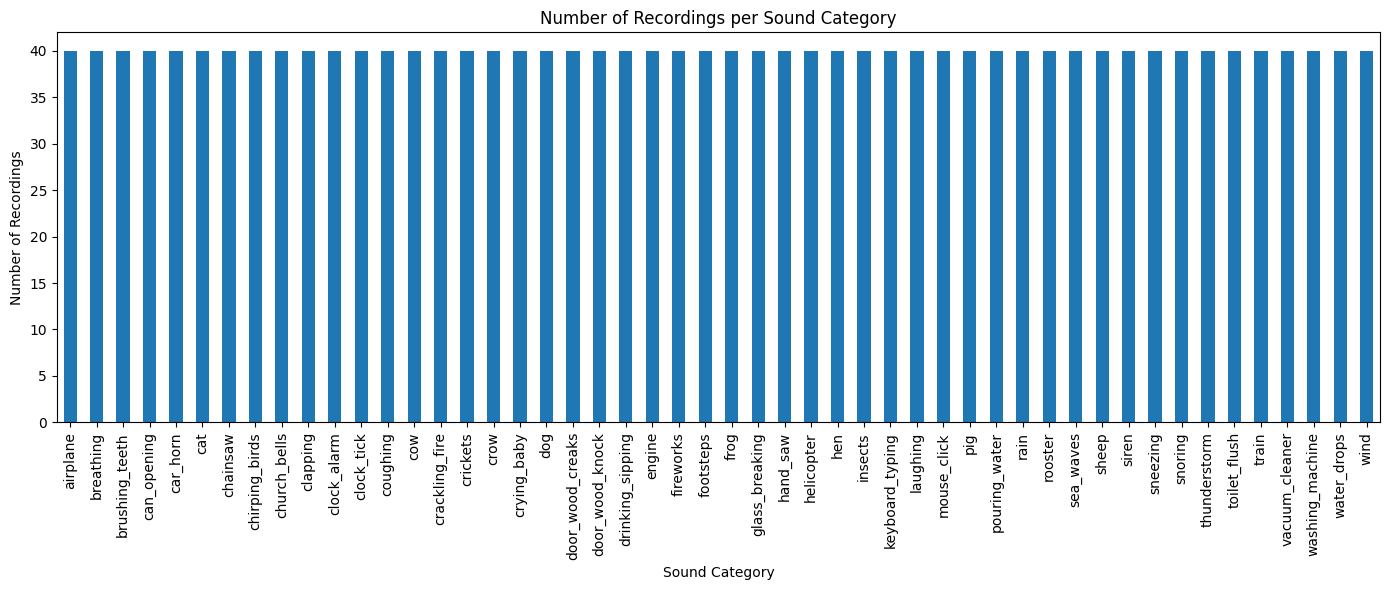

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

category_counts.plot(kind="bar")

plt.title("Number of Recordings per Sound Category")
plt.xlabel("Sound Category")
plt.ylabel("Number of Recordings")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
import librosa
import librosa.display
from IPython.display import Audio, display

# Select one recording
sample = selected_df.iloc[0]

file_path = os.path.join(audio_path, sample["filename"])

audio, sr = librosa.load(file_path, sr=None)

print("Category:", sample["category"])
print("Filename:", sample["filename"])
print("Duration:", len(audio) / sr, "seconds")

import IPython.display as ipd
display(ipd.Audio(audio, rate=sr))

Category: dog
Filename: 1-100032-A-0.wav
Duration: 5.0 seconds


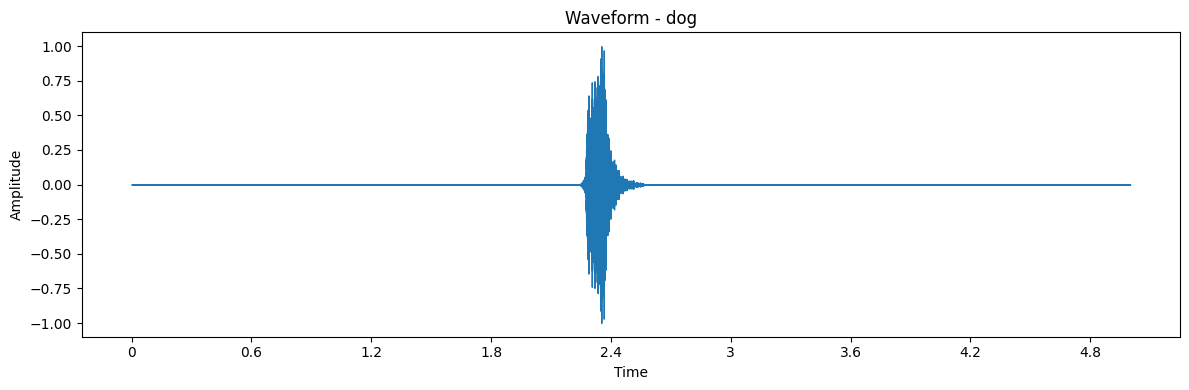

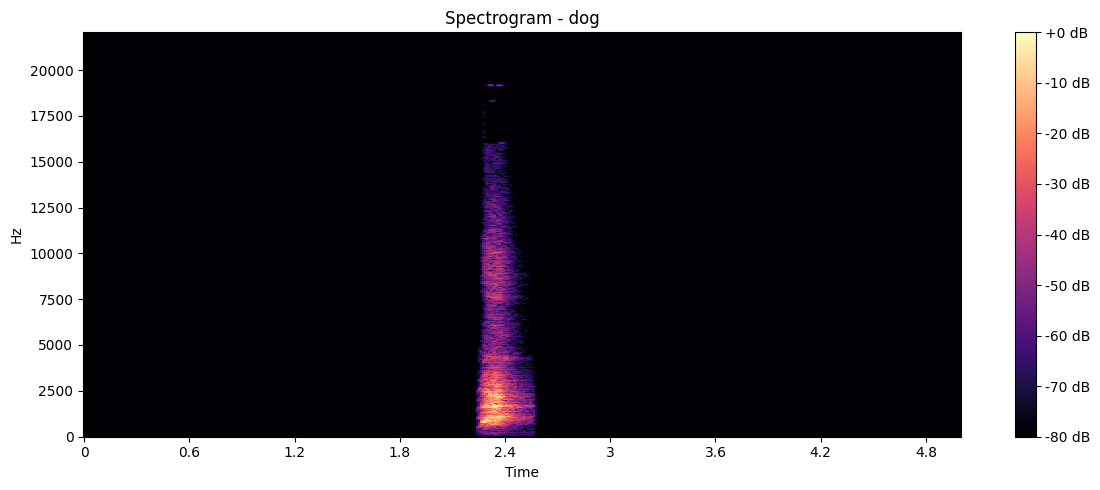

In [ ]:
import matplotlib.pyplot as plt
import librosa.display
import numpy as np

plt.figure(figsize=(12, 4))
librosa.display.waveshow(audio, sr=sr)
plt.title(f"Waveform - {sample['category']}")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

D = librosa.amplitude_to_db(
    np.abs(librosa.stft(audio)),
    ref=np.max
)

plt.figure(figsize=(12, 5))
librosa.display.specshow(
    D,
    sr=sr,
    x_axis="time",
    y_axis="hz",
    cmap="magma"
)
plt.colorbar(format="%+2.0f dB")
plt.title(f"Spectrogram - {sample['category']}")
plt.tight_layout()
plt.show()

spectrogram of different animals

Number of sample recordings: 19


,filename,category
0,1-100032-A-0.wav,dog
1,1-100038-A-14.wav,chirping_birds
4,1-101296-A-19.wav,thunderstorm
8,1-103298-A-9.wav,crow
27,1-118559-A-17.wav,pouring_water
29,1-121951-A-8.wav,sheep
30,1-12653-A-15.wav,water_drops
37,1-137296-A-16.wav,wind
45,1-15689-A-4.wav,frog
49,1-16568-A-3.wav,cow


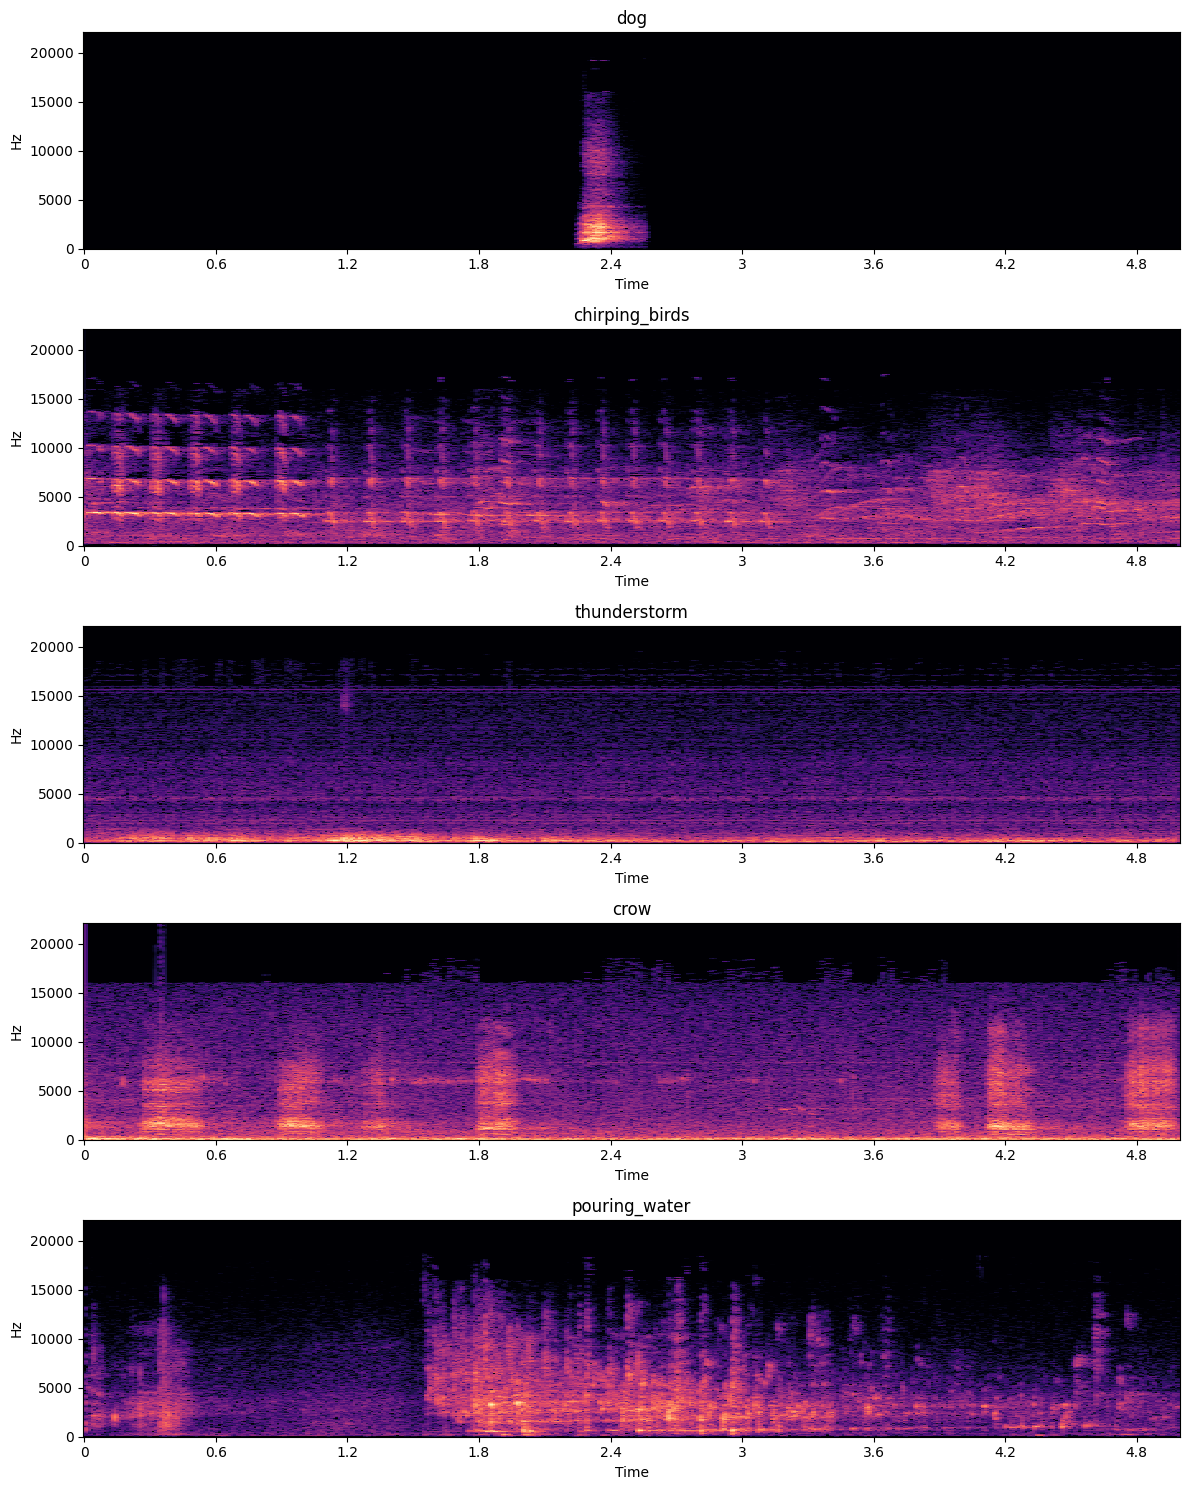

In [ ]:
selected_samples = (
    selected_df.groupby("category", group_keys=False)
    .head(1)
)

print("Number of sample recordings:", len(selected_samples))
display(selected_samples[["filename", "category"]])

fig, axes = plt.subplots(5, 1, figsize=(12, 15))

for ax, (_, row) in zip(axes, selected_samples.iterrows()):

    file_path = os.path.join(audio_path, row["filename"])

    audio, sample_rate = librosa.load(file_path, sr=None)

    D = librosa.stft(audio)
    D_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    librosa.display.specshow(
        D_db,
        sr=sample_rate,
        x_axis="time",
        y_axis="hz",
        ax=ax
    )

    ax.set_title(row["category"])

plt.tight_layout()
plt.show()

feature extraction

In [ ]:
import librosa
import numpy as np
import pandas as pd
import os
from tqdm.notebook import tqdm

feature_data = []

for _, row in tqdm(selected_df.iterrows(), total=len(selected_df)):

    file_path = os.path.join(audio_path, row["filename"])
    audio, sr = librosa.load(file_path, sr=None)

    # Extract 13 MFCC features
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)

    # Extract spectral features
    centroid = librosa.feature.spectral_centroid(y=audio, sr=sr)
    bandwidth = librosa.feature.spectral_bandwidth(y=audio, sr=sr)
    zcr = librosa.feature.zero_crossing_rate(audio)
    rms = librosa.feature.rms(y=audio)

    # Combine all 17 features
    feature_vector = np.concatenate([
        np.mean(mfcc, axis=1),
        [np.mean(centroid)],
        [np.mean(bandwidth)],
        [np.mean(zcr)],
        [np.mean(rms)]
    ])

    feature_data.append({
        "filename": row["filename"],
        "fold": row["fold"],
        "category": row["category"],
        "target": row["target"],
        **{
            f"feature_{i+1}": value
            for i, value in enumerate(feature_vector)
        }
    })

features_df = pd.DataFrame(feature_data)

print("Feature extraction completed!")
print("Dataset shape:", features_df.shape)
display(features_df.head())

  0%|          | 0/760 [00:00<?, ?it/s]

Feature extraction completed!
Dataset shape: (760, 21)


,filename,fold,category,target,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,...,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17
0,1-100032-A-0.wav,1,dog,0,-581.739929,8.207122,-6.658803,-4.290906,-3.034478,0.259279,...,-0.271577,0.518284,0.341884,0.906102,-0.009525,-0.190549,273.927703,255.475244,0.007329,0.007518
1,1-100038-A-14.wav,1,chirping_birds,14,-254.936310,85.839622,-107.103157,31.011576,-39.987736,-17.290342,...,-18.145691,-11.705071,-17.621454,-26.893171,-13.461912,-9.417187,4042.281204,2643.109696,0.157994,0.048115
2,1-101296-A-19.wav,1,thunderstorm,19,-466.622101,144.261398,22.961349,52.213539,2.970681,11.319603,...,0.076406,-8.929120,10.019114,-6.963048,-5.848204,-11.108883,2075.738865,3455.603120,0.027574,0.008841
3,1-101296-B-19.wav,1,thunderstorm,19,-441.774231,153.395920,32.532093,38.864769,0.386356,-1.514097,...,-3.470330,-3.546912,5.873673,-2.664442,-7.838368,-6.315548,1850.646524,3093.555844,0.028877,0.013172
4,1-103298-A-9.wav,1,crow,9,-173.182404,131.663696,-23.350657,44.626896,-16.704086,34.943077,...,24.017622,-3.575602,12.136042,-1.485329,13.711203,4.838859,2675.116865,3530.183905,0.041329,0.123869


In [ ]:
# Check the extracted feature dataset

print("Dataset shape:", features_df.shape)
print("Total recordings:", features_df["filename"].nunique())
print("Number of categories:", features_df["category"].nunique())
print("Number of features:", len([
    col for col in features_df.columns
    if col.startswith("feature_")
]))

print("\nRecordings per category:")
display(features_df["category"].value_counts().sort_index())

print("\nMissing values:")
print(features_df.isnull().sum().sum())

print("\nDuplicate recordings:")
print(features_df["filename"].duplicated().sum())

Dataset shape: (760, 21)
Total recordings: 760
Number of categories: 19
Number of features: 17

Recordings per category:


,count
category,
cat,40
chirping_birds,40
cow,40
crackling_fire,40
crickets,40
crow,40
dog,40
frog,40
hen,40



Missing values:
0

Duplicate recordings:
0


exploratory data analysis-  check for missing/invalid values, feature distribution, similar featues ,etc

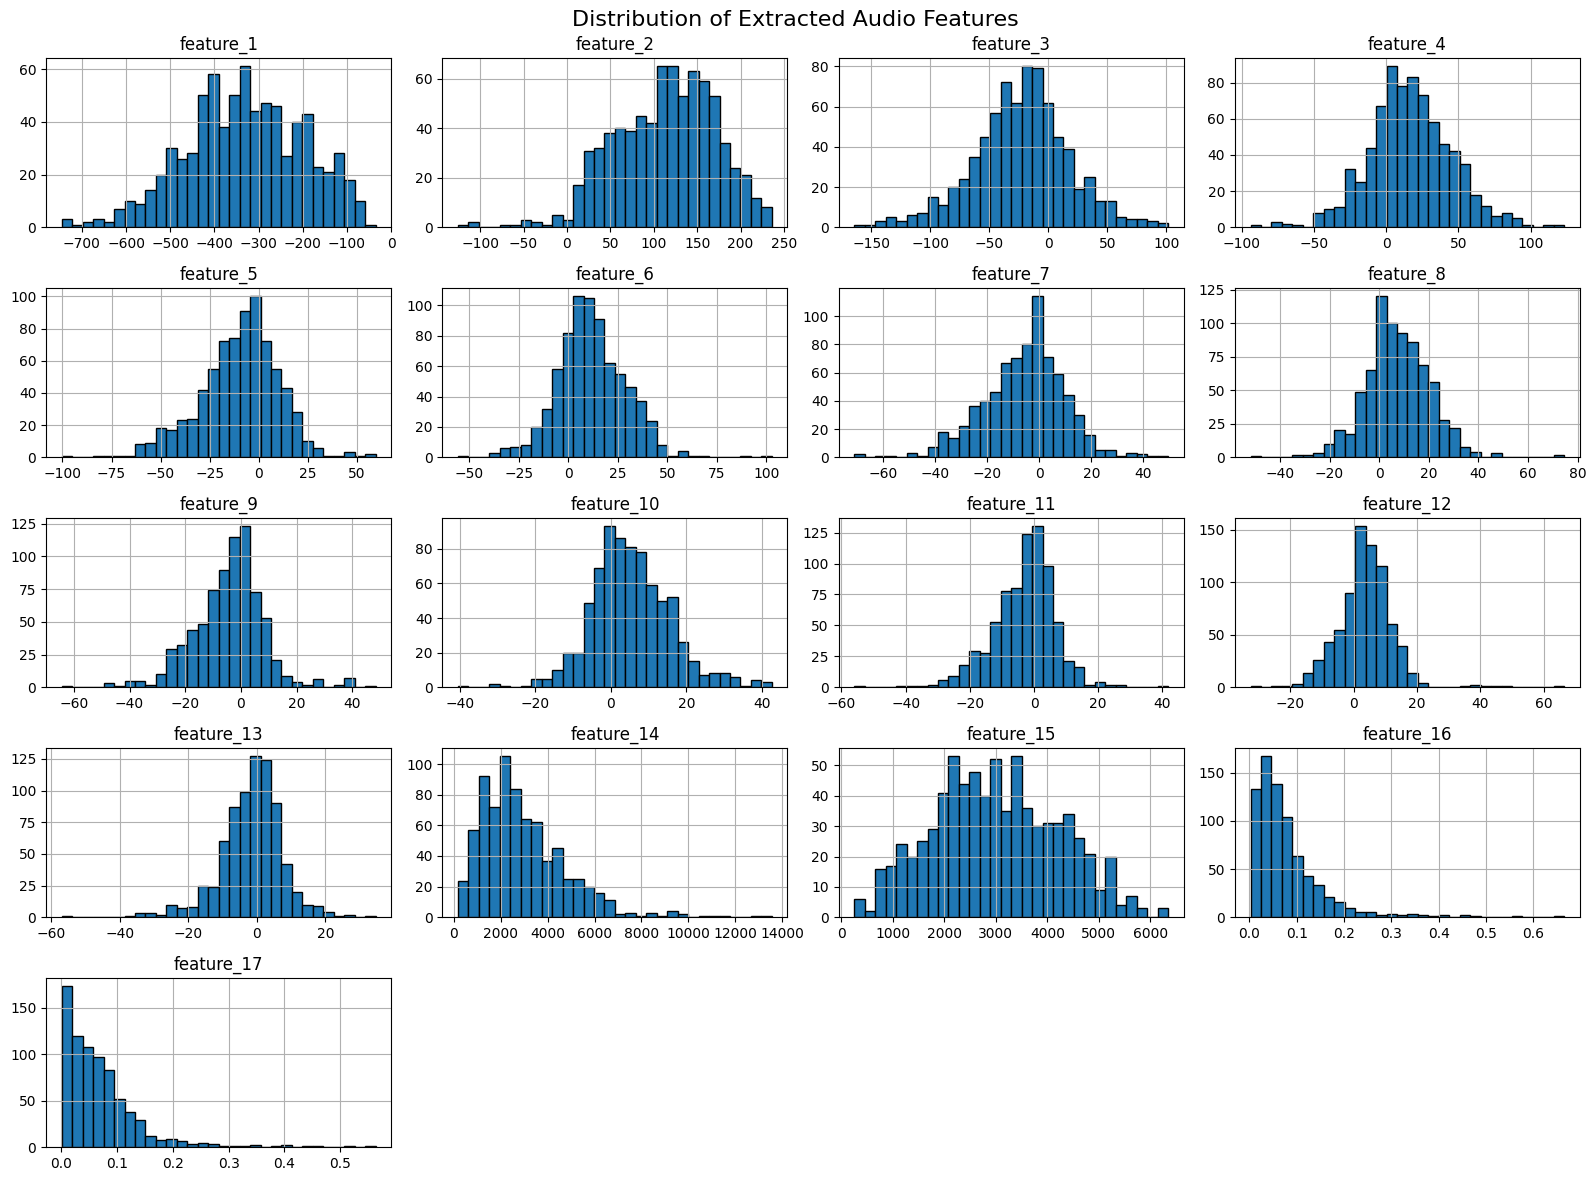

In [ ]:
#feature distribution
import matplotlib.pyplot as plt
import seaborn as sns

feature_cols = [
    col for col in features_df.columns
    if col.startswith("feature_")
]

features_df[feature_cols].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Extracted Audio Features", fontsize=16)
plt.tight_layout()
plt.show()

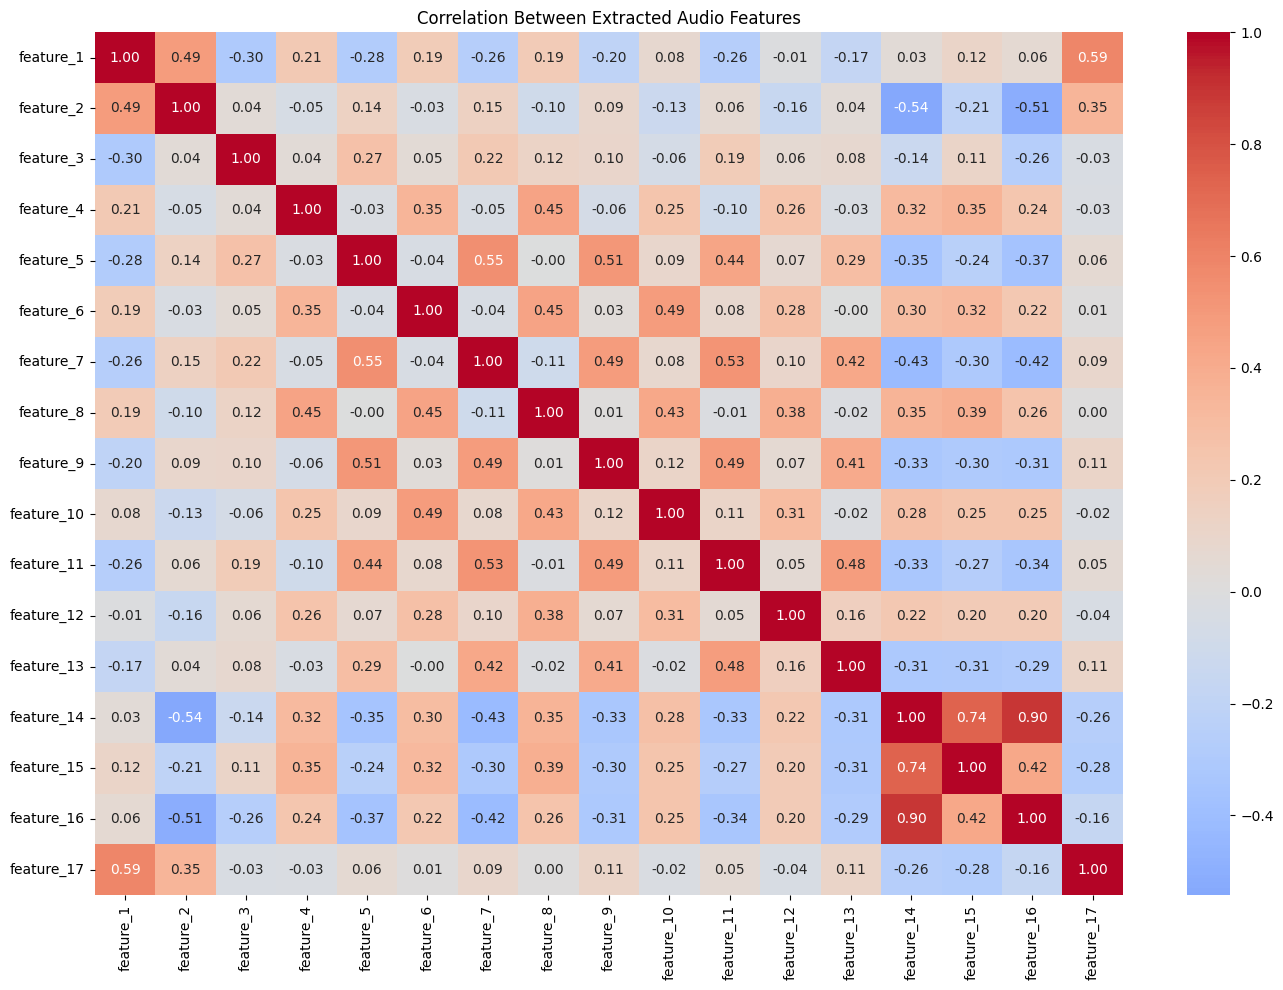

In [ ]:
#feature correlation heatmap
plt.figure(figsize=(14, 10))

correlation_matrix = features_df[feature_cols].corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between Extracted Audio Features")
plt.tight_layout()
plt.show()

applying pca

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

X = features_df[feature_cols]
y = features_df["category"]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Reduce to 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "category": y.values
})

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:",
      sum(pca.explained_variance_ratio_))

Explained variance ratio: [0.26382726 0.16491659]
Total variance retained: 0.4287438454930803


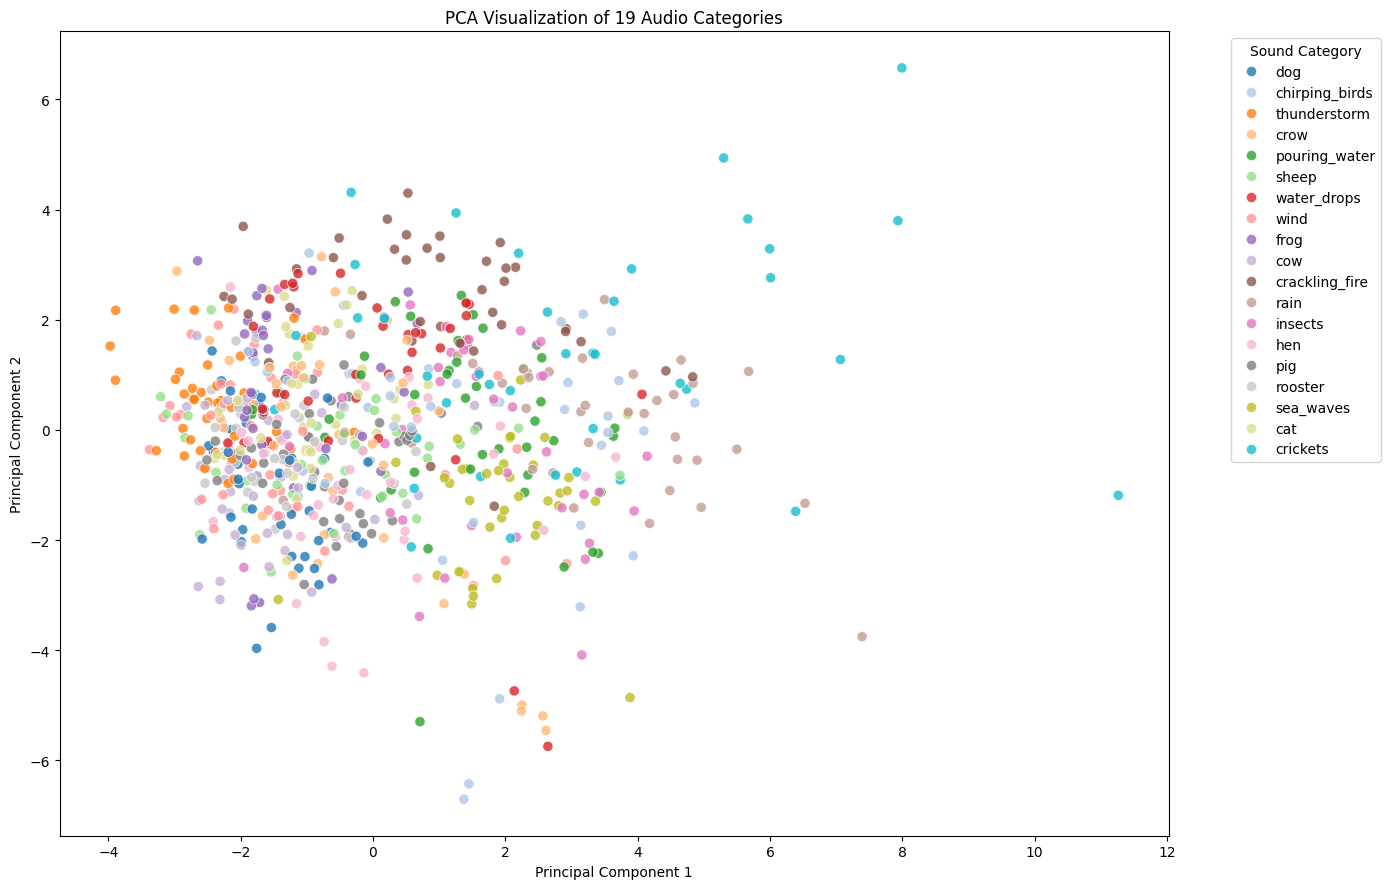

In [ ]:
plt.figure(figsize=(14, 9))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="category",
    palette="tab20",
    s=55,
    alpha=0.8
)

plt.title("PCA Visualization of 19 Audio Categories")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    title="Sound Category"
)
plt.tight_layout()
plt.show()

#### Model training and evaluation

dataset preparation- Each category has 40 recordings, distributed across five folds (8 recordings per category per fold)

In [ ]:
# Separate input features and target labels

X = features_df[feature_cols]
y = features_df["category"]

# Preserve the original ESC-50 fold assignments
folds = features_df["fold"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumber of classes:", y.nunique())
print("Number of folds:", folds.nunique())

print("\nSamples in each fold:")
print(folds.value_counts().sort_index())

print("\nSamples in each category:")
print(y.value_counts().sort_index())

Feature matrix shape: (760, 17)
Target shape: (760,)

Number of classes: 19
Number of folds: 5

Samples in each fold:
fold
1    152
2    152
3    152
4    152
5    152
Name: count, dtype: int64

Samples in each category:
category
cat               40
chirping_birds    40
cow               40
crackling_fire    40
crickets          40
crow              40
dog               40
frog              40
hen               40
insects           40
pig               40
pouring_water     40
rain              40
rooster           40
sea_waves         40
sheep             40
thunderstorm      40
water_drops       40
wind              40
Name: count, dtype: int64


Hyperparameter tuning

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                max_iter=3000,
                random_state=42
            ))
        ]),
        "params": {
            "classifier__C": [0.01, 0.1, 1, 10, 100]
        }
    },

    "SVM": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", SVC(
                kernel="rbf",
                random_state=42
            ))
        ]),
        "params": {
            "classifier__C": [0.1, 1, 10, 100],
            "classifier__gamma": ["scale", 0.01, 0.1, 1]
        }
    },

    "Random Forest": {
        "pipeline": Pipeline([
            ("classifier", RandomForestClassifier(
                random_state=42,
                n_jobs=-1
            ))
        ]),
        "params": {
            "classifier__n_estimators": [100, 200],
            "classifier__max_depth": [None, 10, 20],
            "classifier__min_samples_split": [2, 5]
        }
    }
}

for name, model in models.items():
    print(f"\n{name}")
    print("Number of hyperparameter combinations:",
          __import__("numpy").prod([
              len(values) for values in model["params"].values()
          ]))


Logistic Regression
Number of hyperparameter combinations: 5

SVM
Number of hyperparameter combinations: 16

Random Forest
Number of hyperparameter combinations: 12


##### **Nested cross-validation with hyperparameter tuning**



1.   Keep one fold aside for testing (152 recordings).
2.   Use the remaining four folds (608 recordings) for training.
3.   Perform an inner 4-fold GridSearchCV to find the best hyperparameters.
4.   Evaluate the selected model on the untouched outer test fold.
5.   Repeat for all five outer folds



In [ ]:
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

outer_results = {}

for model_name, model_info in models.items():

    print(f"\n{'='*60}")
    print(f"Evaluating: {model_name}")
    print(f"{'='*60}")

    y_true_all = []
    y_pred_all = []
    fold_scores = []
    best_params_all = []

    for test_fold in sorted(folds.unique()):

        # Outer train-test split
        train_mask = folds != test_fold
        test_mask = folds == test_fold

        X_train = X.loc[train_mask]
        X_test = X.loc[test_mask]

        y_train = y.loc[train_mask]
        y_test = y.loc[test_mask]

        # Inner cross-validation using the remaining four folds
        inner_cv = PredefinedSplit(
            test_fold=folds.loc[train_mask].to_numpy()
        )

        # Hyperparameter tuning
        grid_search = GridSearchCV(
            estimator=model_info["pipeline"],
            param_grid=model_info["params"],
            scoring="f1_macro",
            cv=inner_cv,
            n_jobs=1,
            refit=True
        )

        grid_search.fit(X_train, y_train)

        # Evaluate on the untouched outer test fold
        best_model = grid_search.best_estimator_
        y_pred = best_model.predict(X_test)

        accuracy = accuracy_score(y_test, y_pred)
        macro_f1 = f1_score(y_test, y_pred, average="macro")

        y_true_all.extend(y_test.tolist())
        y_pred_all.extend(y_pred.tolist())

        fold_scores.append({
            "fold": test_fold,
            "accuracy": accuracy,
            "macro_f1": macro_f1
        })

        best_params_all.append(grid_search.best_params_)

        print(f"\nOuter Fold {test_fold}")
        print(f"Accuracy: {accuracy:.4f}")
        print(f"Macro F1: {macro_f1:.4f}")
        print("Best parameters:", grid_search.best_params_)

    # Store results for later analysis
    outer_results[model_name] = {
        "y_true": y_true_all,
        "y_pred": y_pred_all,
        "fold_scores": fold_scores,
        "best_params": best_params_all,
        "accuracy": accuracy_score(y_true_all, y_pred_all),
        "macro_f1": f1_score(
            y_true_all, y_pred_all, average="macro"
        )
    }

    print(f"\nOverall results for {model_name}")
    print(f"Accuracy: {outer_results[model_name]['accuracy']:.4f}")
    print(f"Macro F1: {outer_results[model_name]['macro_f1']:.4f}")


Evaluating: Logistic Regression

Outer Fold 1
Accuracy: 0.4211
Macro F1: 0.4067
Best parameters: {'classifier__C': 1}

Outer Fold 2
Accuracy: 0.5263
Macro F1: 0.5041
Best parameters: {'classifier__C': 1}

Outer Fold 3
Accuracy: 0.5921
Macro F1: 0.5824
Best parameters: {'classifier__C': 1}

Outer Fold 4
Accuracy: 0.5197
Macro F1: 0.4942
Best parameters: {'classifier__C': 10}

Outer Fold 5
Accuracy: 0.5066
Macro F1: 0.4997
Best parameters: {'classifier__C': 1}

Overall results for Logistic Regression
Accuracy: 0.5132
Macro F1: 0.5069

Evaluating: SVM

Outer Fold 1
Accuracy: 0.5461
Macro F1: 0.5446
Best parameters: {'classifier__C': 1, 'classifier__gamma': 'scale'}

Outer Fold 2
Accuracy: 0.5526
Macro F1: 0.5474
Best parameters: {'classifier__C': 1, 'classifier__gamma': 'scale'}

Outer Fold 3
Accuracy: 0.6184
Macro F1: 0.6154
Best parameters: {'classifier__C': 10, 'classifier__gamma': 'scale'}

Outer Fold 4
Accuracy: 0.5724
Macro F1: 0.5695
Best parameters: {'classifier__C': 10, 'classif

model comparison

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

comparison_data = []

for model_name, results in outer_results.items():

    comparison_data.append({
        "Model": model_name,
        "Accuracy": results["accuracy"],
        "Macro F1": results["macro_f1"]
    })

comparison_df = pd.DataFrame(comparison_data)

comparison_df = comparison_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

display(comparison_df)

,Model,Accuracy,Macro F1
0,SVM,0.563158,0.566770
1,Random Forest,0.513158,0.507436
2,Logistic Regression,0.513158,0.506859


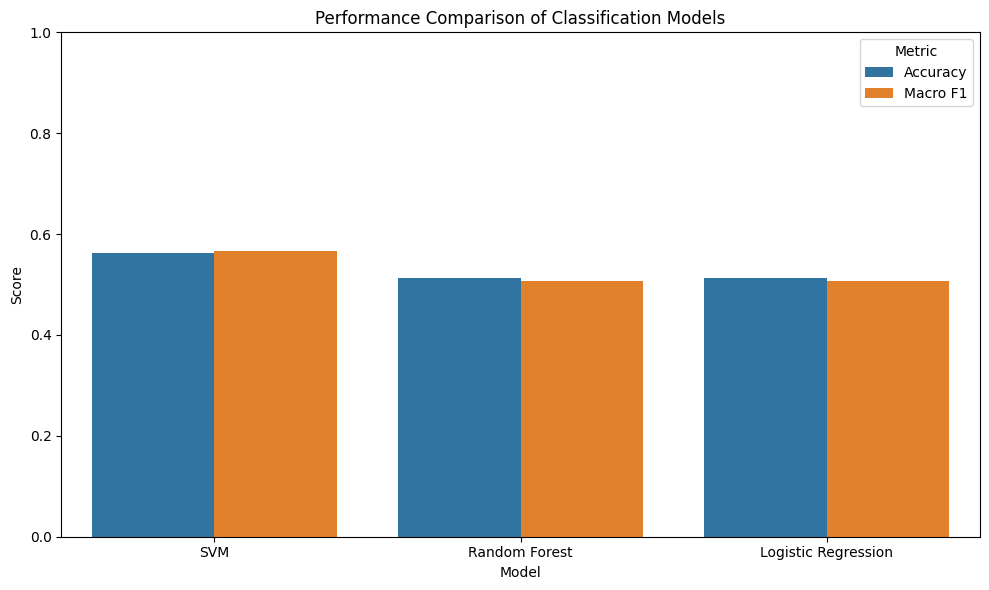

In [ ]:
comparison_plot = comparison_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_plot,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.ylim(0, 1)
plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

Analyse performance for each category -- SVM
 - Which animal sounds are easiest for the model to recognize.
 - Which animal sounds are frequently misclassified.
 - Whether the model performs consistently across categories.

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

for model_name, results in outer_results.items():

    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)

    report = classification_report(
        results["y_true"],
        results["y_pred"],
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    # Display category-wise precision, recall and F1
    display(
        report_df.loc[
            sorted(features_df["category"].unique()),
            ["precision", "recall", "f1-score", "support"]
        ].round(3)
    )


Logistic Regression


,precision,recall,f1-score,support
cat,0.258,0.200,0.225,40.0
chirping_birds,0.344,0.275,0.306,40.0
cow,0.500,0.450,0.474,40.0
crackling_fire,0.644,0.725,0.682,40.0
crickets,0.433,0.325,0.371,40.0
crow,0.525,0.525,0.525,40.0
dog,0.490,0.625,0.549,40.0
frog,0.406,0.325,0.361,40.0
hen,0.488,0.500,0.494,40.0
insects,0.438,0.525,0.477,40.0



SVM


,precision,recall,f1-score,support
cat,0.243,0.425,0.309,40.0
chirping_birds,0.531,0.425,0.472,40.0
cow,0.615,0.600,0.608,40.0
crackling_fire,0.658,0.625,0.641,40.0
crickets,0.614,0.675,0.643,40.0
crow,0.688,0.550,0.611,40.0
dog,0.500,0.575,0.535,40.0
frog,0.778,0.525,0.627,40.0
hen,0.559,0.475,0.514,40.0
insects,0.364,0.400,0.381,40.0



Random Forest


,precision,recall,f1-score,support
cat,0.279,0.300,0.289,40.0
chirping_birds,0.387,0.300,0.338,40.0
cow,0.517,0.375,0.435,40.0
crackling_fire,0.490,0.600,0.539,40.0
crickets,0.625,0.500,0.556,40.0
crow,0.545,0.300,0.387,40.0
dog,0.451,0.575,0.505,40.0
frog,0.733,0.550,0.629,40.0
hen,0.378,0.350,0.364,40.0
insects,0.412,0.350,0.378,40.0


overall svm is performing better than other models, and some categories are easier to distinguish than others

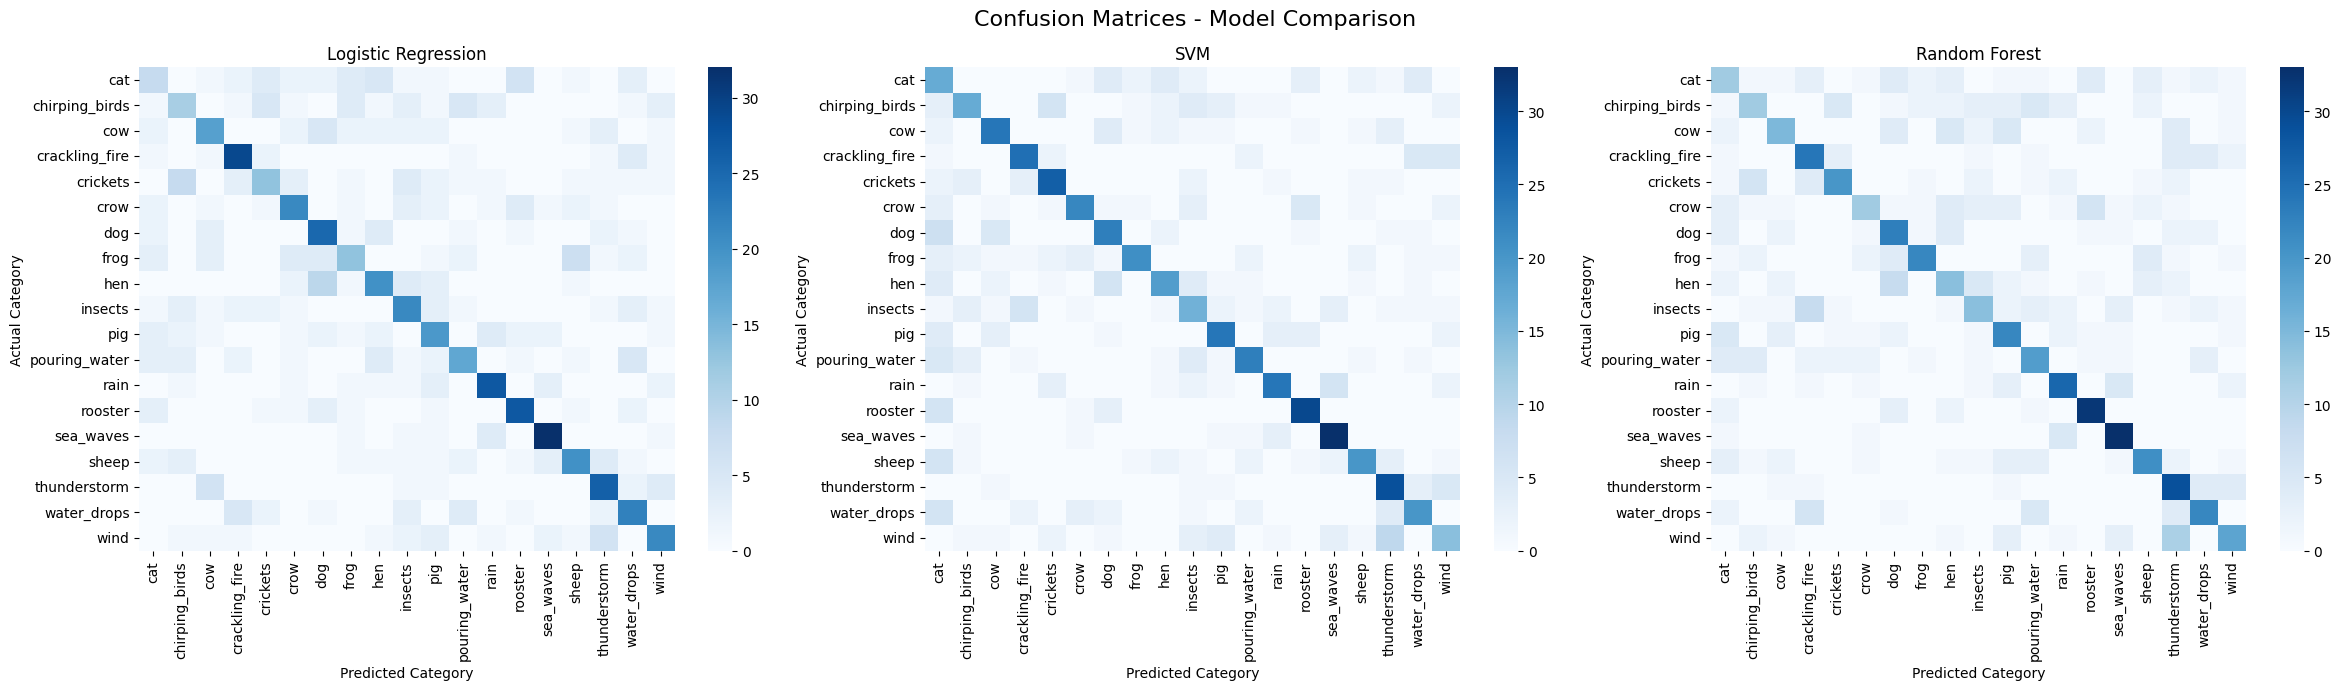

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

categories = sorted(features_df["category"].unique())

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, (model_name, results) in zip(axes, outer_results.items()):

    cm = confusion_matrix(
        results["y_true"],
        results["y_pred"],
        labels=categories
    )

    sns.heatmap(
        cm,
        annot=False,
        cmap="Blues",
        xticklabels=categories,
        yticklabels=categories,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Category")
    ax.set_ylabel("Actual Category")
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle("Confusion Matrices - Model Comparison", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np

categories = sorted(features_df["category"].unique())

for model_name, results in outer_results.items():

    cm = confusion_matrix(
        results["y_true"],
        results["y_pred"],
        labels=categories
    )

    # Remove correct predictions (diagonal)
    cm_off = cm.copy()
    np.fill_diagonal(cm_off, 0)

    # Extract incorrect prediction pairs
    errors = []

    for i in range(len(categories)):
        for j in range(len(categories)):
            if cm_off[i, j] > 0:
                errors.append({
                    "Actual Category": categories[i],
                    "Predicted Category": categories[j],
                    "Misclassified Recordings": cm_off[i, j]
                })

    error_df = pd.DataFrame(errors)

    error_df = error_df.sort_values(
        by="Misclassified Recordings",
        ascending=False
    )

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    display(error_df.head(10))


Logistic Regression


,Actual Category,Predicted Category,Misclassified Recordings
82,hen,dog,9
41,crickets,chirping_birds,8
78,frog,sheep,7
9,cat,rooster,6
151,thunderstorm,cow,6
172,wind,thunderstorm,6
6,cat,hen,5
118,pouring_water,water_drops,5
156,water_drops,crackling_fire,5
20,chirping_birds,pouring_water,5



SVM


,Actual Category,Predicted Category,Misclassified Recordings
147,wind,thunderstorm,9
48,dog,cat,7
10,chirping_birds,crickets,6
68,hen,dog,6
131,water_drops,cat,6
108,rooster,cat,6
116,sheep,cat,6
106,rain,sea_waves,6
77,insects,crackling_fire,6
130,thunderstorm,wind,5



Random Forest


,Actual Category,Predicted Category,Misclassified Recordings
161,wind,thunderstorm,11
90,insects,crackling_fire,8
81,hen,dog,8
41,crickets,chirping_birds,6
58,crow,rooster,6
151,water_drops,crackling_fire,6
27,cow,hen,5
21,chirping_birds,pouring_water,5
153,water_drops,pouring_water,5
125,rain,sea_waves,5


Feature importance

- feature_1 to feature_13 are MFCCs
- feature_14 is spectral centroid
- feature_15 is spectral bandwidth
- feature_16 is ZCR
- feature_17 is RMS energy

In [ ]:
from sklearn.inspection import permutation_importance
import numpy as np
import pandas as pd

all_importances = {}

for model_name, model_info in models.items():

    print(f"Calculating importance: {model_name}")

    fold_importances = []

    for fold_index, test_fold in enumerate(sorted(folds.unique())):

        train_mask = folds != test_fold
        test_mask = folds == test_fold

        X_train = X.loc[train_mask]
        X_test = X.loc[test_mask]

        y_train = y.loc[train_mask]
        y_test = y.loc[test_mask]

        # Get the best parameters for this fold
        best_params = outer_results[model_name]["best_params"][fold_index]

        # Train the model
        best_model = model_info["pipeline"].set_params(**best_params)
        best_model.fit(X_train, y_train)

        # Calculate permutation importance
        result = permutation_importance(
            best_model,
            X_test,
            y_test,
            scoring="f1_macro",
            n_repeats=10,
            random_state=42,
            n_jobs=-1
        )

        fold_importances.append(result.importances_mean)

    # Average importance across all five folds
    all_importances[model_name] = np.mean(
        fold_importances, axis=0
    )

print("\nFeature importance calculation completed!")

Calculating importance: Logistic Regression
Calculating importance: SVM
Calculating importance: Random Forest

Feature importance calculation completed!


In [ ]:
importance_comparison = pd.DataFrame({
    "Feature": feature_cols,
    "Logistic Regression": all_importances["Logistic Regression"],
    "SVM": all_importances["SVM"],
    "Random Forest": all_importances["Random Forest"]
})

display(
    importance_comparison.round(4).sort_values(
        by="SVM",
        ascending=False
    )
)

,Feature,Logistic Regression,SVM,Random Forest
2,feature_3,0.1149,0.1125,0.0706
3,feature_4,0.1209,0.1125,0.0753
1,feature_2,0.0928,0.0860,0.0379
5,feature_6,0.0814,0.0800,0.0004
6,feature_7,0.0654,0.0604,0.0077
0,feature_1,0.1077,0.0578,0.0095
4,feature_5,0.0379,0.0459,0.0129
7,feature_8,0.0389,0.0400,0.0137
8,feature_9,0.0495,0.0396,0.0163
11,feature_12,0.0401,0.0381,0.0060


In [ ]:
importance_comparison = pd.DataFrame({
    "Feature": feature_cols,
    "Logistic Regression": all_importances["Logistic Regression"],
    "SVM": all_importances["SVM"],
    "Random Forest": all_importances["Random Forest"]
})

display(
    importance_comparison.round(4).sort_values(
        by="SVM",
        ascending=False
    )
)

,Feature,Logistic Regression,SVM,Random Forest
2,feature_3,0.1149,0.1125,0.0706
3,feature_4,0.1209,0.1125,0.0753
1,feature_2,0.0928,0.0860,0.0379
5,feature_6,0.0814,0.0800,0.0004
6,feature_7,0.0654,0.0604,0.0077
0,feature_1,0.1077,0.0578,0.0095
4,feature_5,0.0379,0.0459,0.0129
7,feature_8,0.0389,0.0400,0.0137
8,feature_9,0.0495,0.0396,0.0163
11,feature_12,0.0401,0.0381,0.0060


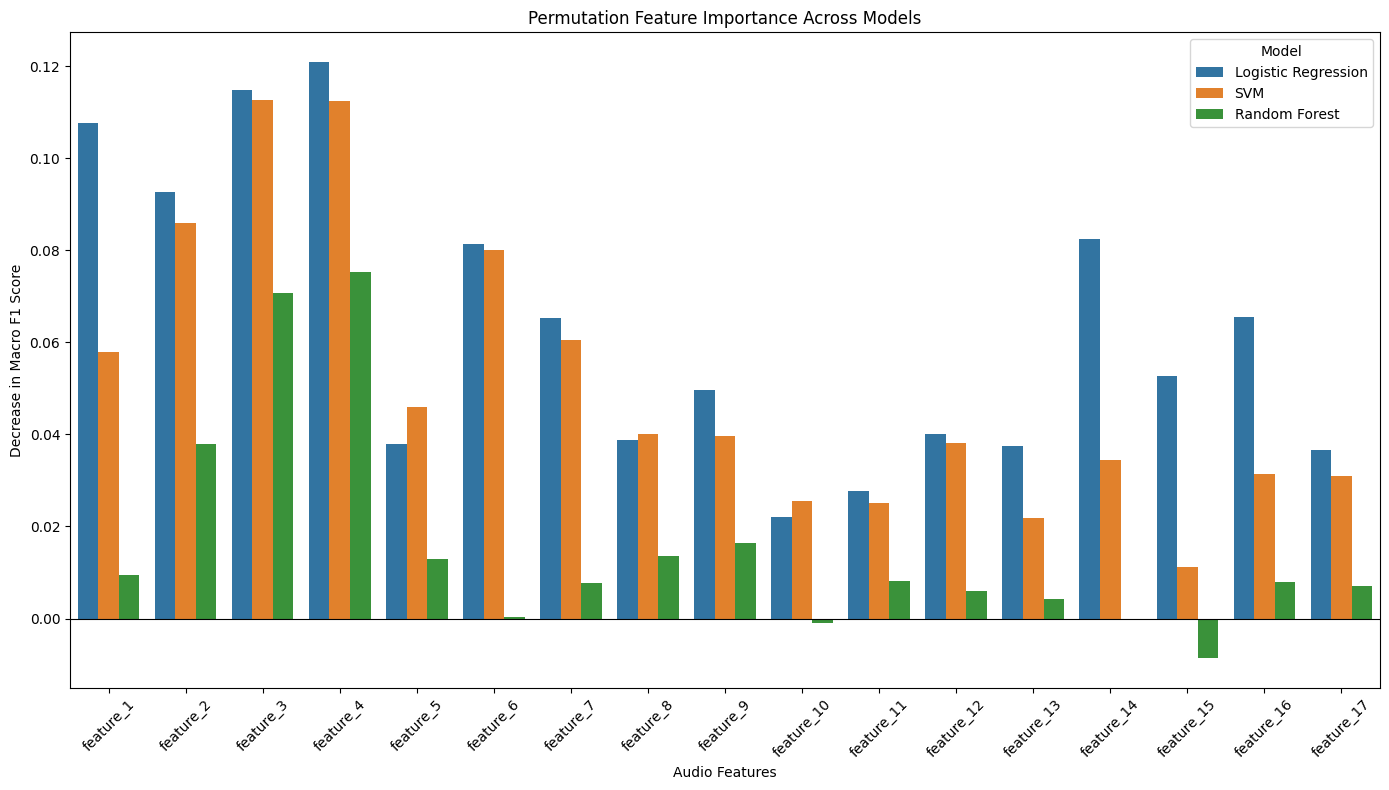

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

importance_plot = importance_comparison.melt(
    id_vars="Feature",
    var_name="Model",
    value_name="Importance"
)

plt.figure(figsize=(14, 8))

sns.barplot(
    data=importance_plot,
    x="Feature",
    y="Importance",
    hue="Model"
)

plt.axhline(0, color="black", linewidth=0.8)

plt.title("Permutation Feature Importance Across Models")
plt.xlabel("Audio Features")
plt.ylabel("Decrease in Macro F1 Score")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

-  Larger positive value → Macro F1 decreases more after shuffling → feature is more important.
-  Value close to zero → Macro F1 barely changes → feature is less important.
-  Negative value → Performance improves slightly after shuffling → feature may be unhelpful or noisy.

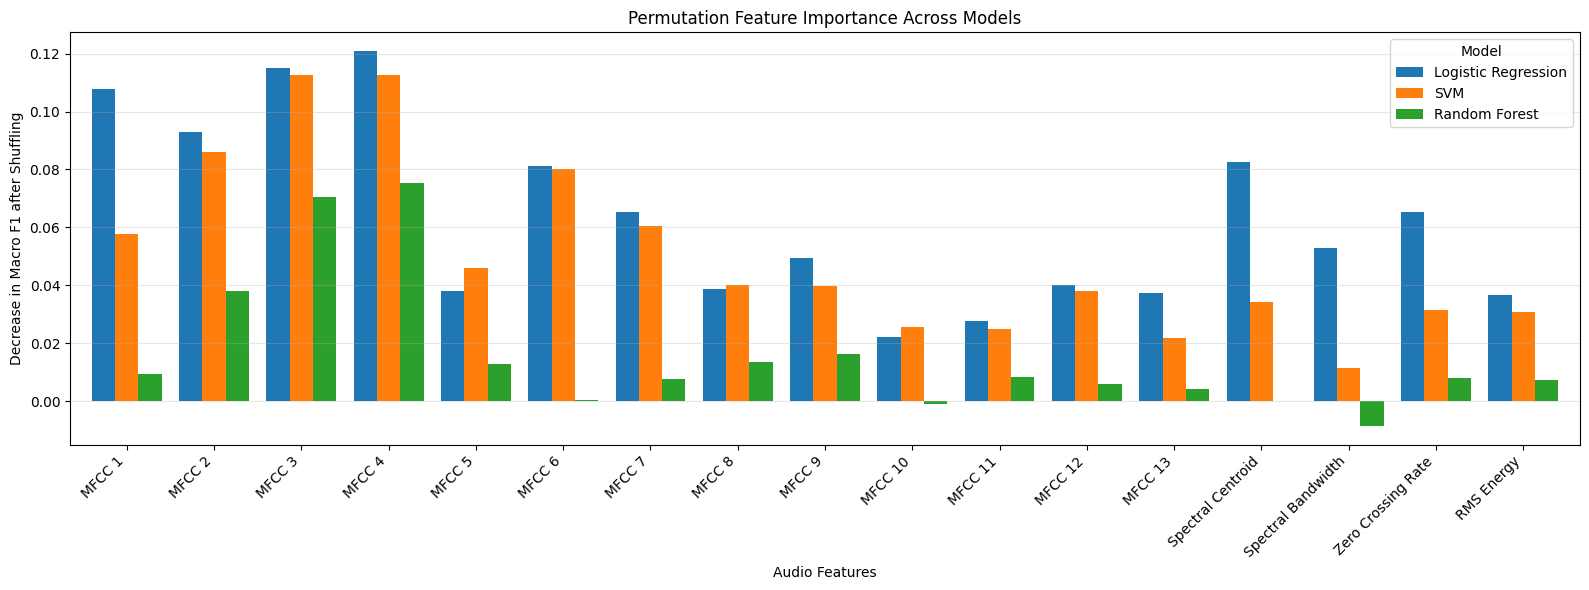

In [ ]:
# Reconstruct the comparison DataFrame
feature_names = [f"feature_{i}" for i in range(1, 18)]

importance_comparison = pd.DataFrame(
    all_importances,
    index=feature_names
)

# Replace generic names with actual audio feature names
feature_mapping = {
    **{f"feature_{i}": f"MFCC {i}" for i in range(1, 14)},
    "feature_14": "Spectral Centroid",
    "feature_15": "Spectral Bandwidth",
    "feature_16": "Zero Crossing Rate",
    "feature_17": "RMS Energy"
}

importance_comparison = importance_comparison.rename(
    index=feature_mapping
)

# Plot
importance_comparison.plot(
    kind="bar",
    figsize=(16, 6),
    width=0.8
)

plt.title("Permutation Feature Importance Across Models")
plt.ylabel("Decrease in Macro F1 after Shuffling")
plt.xlabel("Audio Features")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

final model ranking

In [ ]:
comparison_df = pd.DataFrame({
    "Model": list(outer_results.keys()),
    "Accuracy": [
        outer_results[m]["accuracy"]
        for m in outer_results
    ],
    "Macro F1": [
        outer_results[m]["macro_f1"]
        for m in outer_results
    ]
})

comparison_df = comparison_df.sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)

display(comparison_df)

,Model,Accuracy,Macro F1
0,SVM,0.563158,0.566770
1,Random Forest,0.513158,0.507436
2,Logistic Regression,0.513158,0.506859


## **Training all three models**

1. Use the hyperparameter tuning procedure on the complete dataset, instead of earlier 4 folds
2. Obtain the best hyperparameters.
3. Train the final using all 760 recordings.

In [ ]:
import numpy as np
from sklearn.model_selection import GridSearchCV

cv_splits = []

for test_fold in sorted(folds.unique()):
    train_idx = np.where(folds.to_numpy() != test_fold)[0]
    test_idx = np.where(folds.to_numpy() == test_fold)[0]

    cv_splits.append((train_idx, test_idx))

print("Number of CV splits:", len(cv_splits))

Number of CV splits: 5


In [ ]:
#Tune and train all three models
final_searches = {}
final_models = {}
best_parameters = {}
final_cv_scores = {}

for model_name, model_info in models.items():

    print(f"\nTraining {model_name}...")

    search = GridSearchCV(
        estimator=model_info["pipeline"],
        param_grid=model_info["params"],
        scoring="f1_macro",
        cv=cv_splits,
        n_jobs=-1,
        verbose=1
    )

    search.fit(X, y)

    # Best estimator is automatically refitted on all 760 recordings
    final_searches[model_name] = search
    final_models[model_name] = search.best_estimator_
    best_parameters[model_name] = search.best_params_
    final_cv_scores[model_name] = search.best_score_

    print("Best Parameters:", search.best_params_)
    print("Official-fold CV Macro F1:", search.best_score_)

print("\nAll three models trained successfully!")


Training Logistic Regression...
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best Parameters: {'classifier__C': 1}
Official-fold CV Macro F1: 0.49693417004537715

Training SVM...
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters: {'classifier__C': 1, 'classifier__gamma': 'scale'}
Official-fold CV Macro F1: 0.5615341173520358

Training Random Forest...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters: {'classifier__max_depth': None, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}
Official-fold CV Macro F1: 0.5238273360613828

All three models trained successfully!


In [ ]:
final_comparison = pd.DataFrame({
    "Model": list(final_cv_scores.keys()),
    "Best Parameters": list(best_parameters.values()),
    "CV Macro F1": list(final_cv_scores.values())
})

final_comparison = final_comparison.sort_values(
    by="CV Macro F1",
    ascending=False
)

display(final_comparison)

,Model,Best Parameters,CV Macro F1
1,SVM,"{'classifier__C': 1, 'classifier__gamma': 'sca...",0.561534
2,Random Forest,"{'classifier__max_depth': None, 'classifier__m...",0.523827
0,Logistic Regression,{'classifier__C': 1},0.496934


**saving the trained models**

In [ ]:
import joblib

model_bundle = {
    "models": final_models,
    "best_parameters": best_parameters,
    "cv_scores": final_cv_scores,
    "feature_cols": feature_cols,
    "selected_categories": selected_categories
}

joblib.dump(model_bundle, "all_three_sound_classifiers.pkl")

print("All three models saved successfully!")

All three models saved successfully!


In [ ]:
#download
from google.colab import files

files.download("all_three_sound_classifiers.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

test

In [ ]:
#upload
from google.colab import files

uploaded = files.upload()

audio_path = next(iter(uploaded.keys()))

print("Uploaded file:", audio_path)

Saving mixkit-heavy-rain-drops-2399.wav to mixkit-heavy-rain-drops-2399 (1).wav
Uploaded file: mixkit-heavy-rain-drops-2399 (1).wav


In [ ]:
import numpy as np
import pandas as pd
import librosa

# Extract audio features
def extract_features(file_path):
    audio, sr = librosa.load(file_path, sr=None)

    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)
    centroid = librosa.feature.spectral_centroid(y=audio, sr=sr)
    bandwidth = librosa.feature.spectral_bandwidth(y=audio, sr=sr)
    zcr = librosa.feature.zero_crossing_rate(audio)
    rms = librosa.feature.rms(y=audio)

    feature_vector = np.concatenate([
        np.mean(mfcc, axis=1),
        [np.mean(centroid)],
        [np.mean(bandwidth)],
        [np.mean(zcr)],
        [np.mean(rms)]
    ])

    return feature_vector


# Extract features from uploaded audio
new_features = extract_features(audio_path)

assert len(new_features) == 17, (
    f"Expected 17 features, got {len(new_features)}"
)

# Convert into DataFrame
input_df = pd.DataFrame(
    [new_features],
    columns=feature_cols
)


# Predict using all three trained models
predictions = {}

for model_name, model in final_models.items():
    predictions[model_name] = model.predict(input_df)[0]


# Display results
results_df = pd.DataFrame(
    list(predictions.items()),
    columns=["Model", "Predicted Sound Category"]
)

display(results_df)

,Model,Predicted Sound Category
0,Logistic Regression,rain
1,SVM,rain
2,Random Forest,rain
